# Prepare the Data

We follow the preparation checklist:

| Step | What we do | Section |
|---|---|---|
| 1. Data cleaning | Outliers and missing values | [1. Data cleaning](#1.-Data-cleaning) |
| 2. Feature selection | Remove redundant / useless features, using a **random forest just to get information** | [2. Feature selection](#2.-Feature-selection) |
| 3. Feature engineering | Transforms, the manual-rule flag, missing flags, **polynomial features** | [3. Feature engineering](#3.-Feature-engineering) |
| 4. Feature scaling | Standardize or robust-scale | [4. Feature scaling](#4.-Feature-scaling) |
| Build and save | `preprocessor.pkl`, checked on train, test and `generate_samples()`-style input | [5. The preprocessor](#5.-The-preprocessor) |

**Ground rules**

* Every decision uses the **training years only**. The test set is loaded once, only to check that the preprocessor runs on it.
* Everything that learns something from the data (medians, scaling, thresholds) is done **inside a scikit-learn pipeline**, so during cross-validation it is learned from the training folds only and nothing leaks from the validation fold.
* The preparation code is in **`early_spring_prep.py`** (next to this notebook), not only here. `preprocessor.pkl` is a pickle, and to load a pickle Python must be able to import the classes it was made from. Keeping them in a `.py` file means the Training notebook (and `model.pkl` later) can load it.
* Everything that was in this notebook before the check-in but was really *exploration* (missing values, the label over time, the profit baselines) has moved to the Exploration notebook. The model comparison (logistic regression, precision/recall, ROC, the model list) belongs in the Training notebook.

In [1]:
# Imports
import pickle
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate, learning_curve
from sklearn.pipeline import Pipeline


import early_spring_prep as prep
from early_spring_prep import TARGET, make_preprocessor, profit_per_year, profit_score

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42

`early_spring_prep.py` provides:

* `FeatureEngineer`: picks the columns, can apply `log1p` to the skewed `gdd`, and can add the manual-rule flag and "was missing" flags.
* `PairwiseProducts`: polynomial (degree-2) features for a few chosen columns.
* `ToFrame`: runs an imputer or scaler but keeps the column names (so we can always see which column is which).
* `make_preprocessor(...)`: chains them: **engineer → impute → scale → polynomial**.
* `profit_per_year` and `profit_score`: the business measure from Frame the Problem (step 5), usable as a scikit-learn scorer.

In [2]:
train_set = pd.read_parquet("train_set.parquet")
test_set = pd.read_parquet("test_set.parquet")     # only used to check that the preprocessor works on it

X_train = train_set.drop(columns=TARGET)
y_train = train_set[TARGET].astype(bool)
print(f"Training set: {X_train.shape[0]} years x {X_train.shape[1]} columns, {y_train.sum()} early springs")
print(f"Test set:     {test_set.shape[0]} years (not used for any decision in this notebook)")
X_train.dtypes.value_counts()

Training set: 57 years x 21 columns, 11 early springs
Test set:     15 years (not used for any decision in this notebook)


float64    19
int64       1
boolean     1
Name: count, dtype: int64

The training set has 57 years and 21 feature columns: 19 numeric features, `year` (integer) and `phil_early` (a nullable boolean, `True` = Phil called an early spring). The preprocessor has to cope with that boolean type too, because that is exactly what `generate_samples()` returns.

In [3]:
# One cross-validation setup for every experiment in this notebook:
# 5 folds (each fold keeps the early/late ratio) repeated 10 times with different shuffles.
# With 11 early springs, one 5-fold split has only ~2 early springs per fold, so a single run is very noisy.
CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)
SCORING = {"auc": "roc_auc", "profit": profit_score}


def evaluate(model, X=X_train, y=y_train, **prep_params):
    """Cross-validate preprocessor + model. Returns train and validation scores (mean over 50 fits)."""
    pipe = Pipeline([("prep", make_preprocessor(**prep_params)), ("model", model)])
    r = cross_validate(pipe, X, y, cv=CV, scoring=SCORING, return_train_score=True)
    return pd.Series({
        "train AUC": r["train_auc"].mean(), "CV AUC": r["test_auc"].mean(), "CV AUC sd": r["test_auc"].std(),
        "train profit": r["train_profit"].mean(), "CV profit": r["test_profit"].mean(),
    })

**How we judge each preparation choice.** We can't judge preparation on its own, so each option is tried with a simple model (usually a strongly regularized logistic regression, sometimes a random forest) and scored with **repeated stratified 5-fold cross-validation** (5 folds × 10 repeats = 50 fits):

* **CV AUC** (ROC AUC on the held-out folds) is the main number here: it measures how well the model *ranks* early vs. late years without picking a threshold. 0.5 = coin flip, 1.0 = perfect.
* **CV AUC sd** is the spread across the 50 fits. It is large (~0.17) because each held-out fold has only ~2 early springs. **Differences smaller than ~0.02–0.03 between options are noise**, so we only act on bigger differences or on choices that also make physical sense.
* **train AUC** is the score on the data the model was fitted on. The **gap** between train and CV tells us about over- or underfitting.
* **CV profit** is the profit per year (in R) when buying whenever P(early) > 0.2. It is shown for reference; the threshold itself is tuned in the Training notebook.

# 1. Data cleaning

### 1a. Outliers

The noise audit in Exploration found **no impossible values** in the raw daily data (no max below min, no negative snow, nothing outside the sensor ranges). So the question here is only whether some **years** are extreme enough to hurt the model.

In [4]:
# Yearly outliers: values more than 1.5 IQR outside the middle 50% of the training years
num = X_train.drop(columns=["year", "phil_early"]).astype(float)
q1, q3 = num.quantile(0.25), num.quantile(0.75)
low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
flags = (num.lt(low) | num.gt(high))

outliers = (flags.stack().loc[lambda s: s].reset_index()
            .rename(columns={"level_0": "row", "level_1": "feature"}).drop(columns=0))
outliers["year"] = train_set.loc[outliers["row"], "year"].to_numpy()
outliers["value"] = [num.at[r, f] for r, f in zip(outliers["row"], outliers["feature"])]
outliers["early_spring"] = y_train.loc[outliers["row"]].to_numpy()
print(f"{len(outliers)} outlying values in {outliers['year'].nunique()} years "
      f"({flags.any(axis=1).mean():.0%} of training years)\n")
outliers.drop(columns="row").sort_values(["feature", "year"]).round(2).reset_index(drop=True)

17 outlying values in 12 years (21% of training years)



,feature,year,value,early_spring
0,air_feb,1978,17.07,False
1,air_feb_late,1963,15.57,False
2,ao_jan,1989,3.11,False
3,gdd,1950,136.50,False
4,gdd,2000,138.00,True
5,gdd,2002,130.50,False
6,soil_feb,1949,2.36,True
7,soil_feb,1980,-2.89,False
8,soil_feb_late,1949,3.26,True
9,soil_feb_late,1961,2.63,False


Using the usual 1.5 × IQR rule, 12 of the 57 years have at least one extreme value. They are all **real, memorable winters**, not errors:

* **1978**: the coldest February in the data (17 °F average), and **1963**: the coldest late February. Both were famously harsh winters.
* **1976**: the warmest late-February soil (4.4 °C) and the biggest soil warm-up since January.
* **1968**: frozen soil (−4 °C late-February average) after a very cold spell.
* **1949** and **2000**: very warm winters (warm soil, high `gdd`), and both were early springs.
* **1950** and **2002**: high `gdd` but not early, a reminder that one warm signal is not enough.

**Decision: keep all of them.** They are exactly the cold (or warm) years the model must learn to recognize, and with 57 years we can't afford to drop any. To limit their pull:

* tree models (random forest, boosting) are not affected by extreme values at all;
* `RobustScaler` (median/IQR scaling) is available as an option for the linear models;
* strong regularization (section 3c) keeps a linear model from chasing single years.

### 1b. Missing values

In [5]:
# Missing values in the training set, and which years they are in
miss = X_train.isna()
by_year = (train_set.loc[miss.any(axis=1), ["year", TARGET]]
           .assign(missing_columns=miss[miss.any(axis=1)].apply(lambda r: ", ".join(r.index[r]), axis=1)))
print(f"Cells missing: {miss.sum().sum()} of {miss.size} ({miss.values.mean():.1%}); rows with any gap: {len(by_year)}\n")
by_year

Cells missing: 34 of 1197 (2.8%); rows with any gap: 5



,year,early_spring,missing_columns
0,1947,False,"oni_son, oni_ond, oni_ndj, oni_trend, ao_nov, ..."
1,1948,False,"oni_son, oni_ond, oni_ndj, oni_trend, ao_nov, ..."
2,1949,True,"oni_son, oni_ond, oni_ndj, oni_trend, ao_nov, ..."
3,1950,False,"oni_son, oni_ond, oni_ndj, oni_trend, ao_nov, ..."
51,2004,False,"cold_days, air_feb_late, air_feb"


Only 2.8% of the cells are missing, in **5 years**:

| Years | Missing | Why |
|---|---|---|
| 1947–1950 | ONI and AO features | NOAA's indices start in 1950 and our features use the fall/winter before each spring |
| 2004 | the February air features | The station recorded no air temperatures for all of February 2004 |

(One thing to know: `gdd` for 2004 is **not** missing, but it only adds up January because February has no readings, so it is too small for that year. It is one year out of 57 and `gdd` turns out not to matter, so we leave it.)

**The client's rule** is that *years* with missing data are dropped and never filled in. These 5 years are not missing: each has a label and most of its features. What's missing are a few **cells**. One of these years (1949) is an **early spring**, and we only have 11.

We compared four ways to handle the gaps (with all 21 columns and the same strongly regularized logistic regression):

In [6]:
# Compare ways of handling the gaps with a simple, strongly regularized model
lr = LogisticRegression(C=0.1, max_iter=5000)
complete_rows = ~X_train.isna().any(axis=1)

options = {
    "1. drop rows with any gap":            evaluate(lr, X_train[complete_rows], y_train[complete_rows], feature_set="all"),
    "2. drop columns with any gap":         evaluate(lr, X_train.loc[:, ~X_train.isna().any()], y_train, feature_set="all",
                                                     add_missing_flags=False, add_rule_flag=False),
    "3. fill with training median":         evaluate(lr, feature_set="all", add_missing_flags=False),
    "4. median + 'was missing' flags":      evaluate(lr, feature_set="all", add_missing_flags=True),
}
pd.DataFrame(options).T.round(3)

,train AUC,CV AUC,CV AUC sd,train profit,CV profit
1. drop rows with any gap,0.853,0.603,0.194,0.073,0.008
2. drop columns with any gap,0.820,0.674,0.191,0.077,0.050
3. fill with training median,0.860,0.654,0.170,0.075,0.032
4. median + 'was missing' flags,0.860,0.642,0.159,0.075,0.029


1. **Drop rows with any gap**: removes 5 years, including 1 of the 11 early springs, and is by far the worst (lowest CV AUC). Not an option.
2. **Drop columns with any gap**: removes all ONI/AO features plus the February air features, including `air_feb`, the single strongest predictor. It scores well here only because the ONI/AO columns it drops are weak (see section 2) and "all columns" is too many anyway. Too blunt as a general rule.
3. **Fill each gap with the training median** (`SimpleImputer(strategy="median")`): keeps every year and every feature. The median is learned from the training folds only, so nothing leaks.
4. **Median + "was missing" flags**: adds `indices_missing` and `air_missing`. These flags mark only 4 and 1 training years, so the model can't learn much from them and they slightly hurt.

**Decision: fill the few missing cells with the training median (option 3).** This is not the same as inventing a year: the year's label and all its other features are real, and the median is a neutral value that pushes the prediction neither way. The flags stay available as a tunable option (`add_missing_flags`). Note that the default feature set chosen below (`small`) doesn't use ONI/AO, so in practice the only gap left to fill is `air_feb` for 2004.

# 2. Feature selection

With 57 years and 21 columns, the model has about one column for every three years. Exploration showed that many columns are **near-duplicates** and several are **weak**. Too many weak or duplicated features make models overfit (they find patterns in the noise) and make linear models unstable.

### 2a. Groups of redundant features

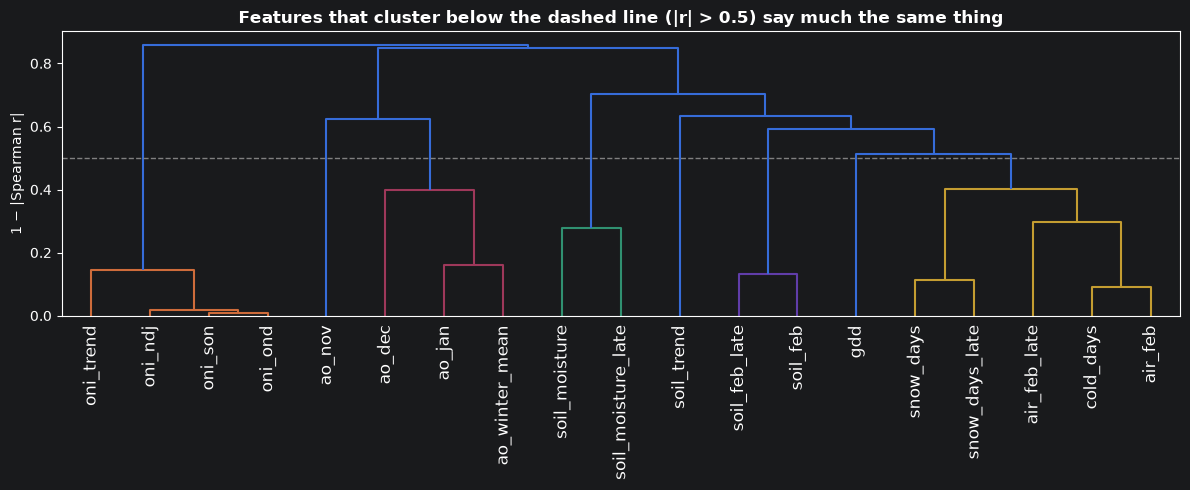

,features in the cluster
cluster,
1,"oni_son, oni_ond, oni_ndj, oni_trend"
2,"ao_dec, ao_jan, ao_winter_mean"
3,ao_nov
4,"soil_moisture, soil_moisture_late"
5,"soil_feb_late, soil_feb"
6,"snow_days, cold_days, air_feb_late, air_feb, s..."
7,gdd
8,soil_trend


In [7]:
# Groups of near-duplicate features: hierarchical clustering on |correlation| (Spearman, rank-based)
feats = X_train.drop(columns=["year", "phil_early"]).astype(float)
corr = feats.corr(method="spearman").fillna(0)
dist = 1 - corr.abs()
link = hierarchy.average(squareform(dist.values, checks=False))

fig, ax = plt.subplots(figsize=(12, 5))
hierarchy.dendrogram(link, labels=corr.columns.tolist(), leaf_rotation=90, ax=ax, color_threshold=0.5)
ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
ax.set_ylabel("1 − |Spearman r|")
ax.set_title("Features that cluster below the dashed line (|r| > 0.5) say much the same thing", fontweight="bold")
plt.tight_layout()
plt.show()

clusters = pd.Series(hierarchy.fcluster(link, t=0.5, criterion="distance"), index=corr.columns, name="cluster")
clusters.groupby(clusters).apply(lambda s: ", ".join(s.index)).to_frame("features in the cluster")

The dendrogram groups features by how strongly they move together (rank correlation). Features that join below the dashed line (|r| > 0.5) carry largely the same information:

* **February cold and snow** form one cluster: `air_feb`, `cold_days` (r = −0.91 with `air_feb`), `air_feb_late`, `snow_days`, `snow_days_late`. Cold Februaries are snowy Februaries.
* **Soil temperature**: `soil_feb` and `soil_feb_late`.
* **Soil moisture**: `soil_moisture` and `soil_moisture_late`.
* **ONI**: all four ONI features. **AO**: `ao_dec`, `ao_jan`, `ao_winter_mean` (and `ao_nov` on its own).
* `gdd` and `soil_trend` stand on their own.

From each group we only need one or two members. To decide *which* ones, we use a random forest.

### 2b. Random forest, just to get information

The check-in feedback was to run a random forest here **only to learn about the features**, not as the final model. Random forests are useful for this because they:

* handle every feature without scaling and are not bothered by skew or outliers;
* pick up non-linear effects and interactions (e.g. "warm *and* no snow") that correlations miss;
* give two kinds of importance:
  * **impurity importance**: how much each feature was used to split the trees. It is computed on the training data and tends to favor features with many distinct values.
  * **permutation importance**: how much the AUC on **held-out** years drops when one feature is shuffled. This is the more honest one, because it measures what the feature does for *new* years.

We add a column of **pure random noise** as a yardstick: any real feature should be more important than random noise. Features that can't beat it are candidates to drop.

In [8]:
# Random forest on ALL features, only to learn which features carry information.
# A column of pure random noise is added as a yardstick: a real feature should beat it.
rng = np.random.default_rng(RANDOM_STATE)
X_noise = X_train.assign(random_noise=rng.normal(size=len(X_train)))

rf_prep = make_preprocessor(feature_set="all", log_skewed=False, add_rule_flag=False,
                            add_missing_flags=False, scaler="none")
X_rf = rf_prep.fit_transform(X_noise)

rf = RandomForestClassifier(n_estimators=1000, min_samples_leaf=3, max_features="sqrt",
                            oob_score=True, random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_rf, y_train)
print(f"Out-of-bag accuracy: {rf.oob_score_:.2f} (always saying 'not early' gets {1 - y_train.mean():.2f})")

impurity = pd.Series(rf.feature_importances_, index=X_rf.columns, name="impurity importance")

Out-of-bag accuracy: 0.77 (always saying 'not early' gets 0.81)


The out-of-bag accuracy (each tree scored on the years it did not see) is below "always say not early". That's expected: with 19% early springs a default 0.5 threshold almost never says "early". It is the reason we judge models by AUC and profit, not accuracy.

In [9]:
# Permutation importance, measured on data the forest did NOT train on:
# for each CV split, fit on 4/5 of the years, then shuffle one feature at a time in the held-out 1/5
# and see how much the AUC drops. Averaged over 5 folds x 10 repeats.
perm = []
for train_idx, val_idx in CV.split(X_rf, y_train):
    m = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1)
    m.fit(X_rf.iloc[train_idx], y_train.iloc[train_idx])
    r = permutation_importance(m, X_rf.iloc[val_idx], y_train.iloc[val_idx], scoring="roc_auc",
                               n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
    perm.append(r.importances_mean)
perm = pd.DataFrame(perm, columns=X_rf.columns)

importance = pd.DataFrame({
    "impurity importance": impurity,
    "permutation (AUC drop)": perm.mean(),
    "permutation sd": perm.std(),
    "corr with label": X_noise.astype(float).corrwith(y_train.astype(float)),
}).sort_values("permutation (AUC drop)", ascending=False)
importance["beats noise?"] = importance["permutation (AUC drop)"] > importance.loc["random_noise", "permutation (AUC drop)"]
importance.round(3)

,impurity importance,permutation (AUC drop),permutation sd,corr with label,beats noise?
air_feb,0.116,0.032,0.072,0.400,True
cold_days,0.083,0.030,0.066,-0.310,True
soil_moisture,0.076,0.007,0.053,0.286,True
snow_days,0.060,0.006,0.053,-0.315,True
ao_jan,0.023,0.001,0.025,0.072,True
phil_early,0.000,-0.000,0.003,-0.090,True
soil_trend,0.048,-0.002,0.028,0.159,True
soil_feb,0.063,-0.004,0.055,0.241,True
snow_days_late,0.020,-0.004,0.016,-0.252,True
oni_trend,0.021,-0.004,0.021,-0.066,True


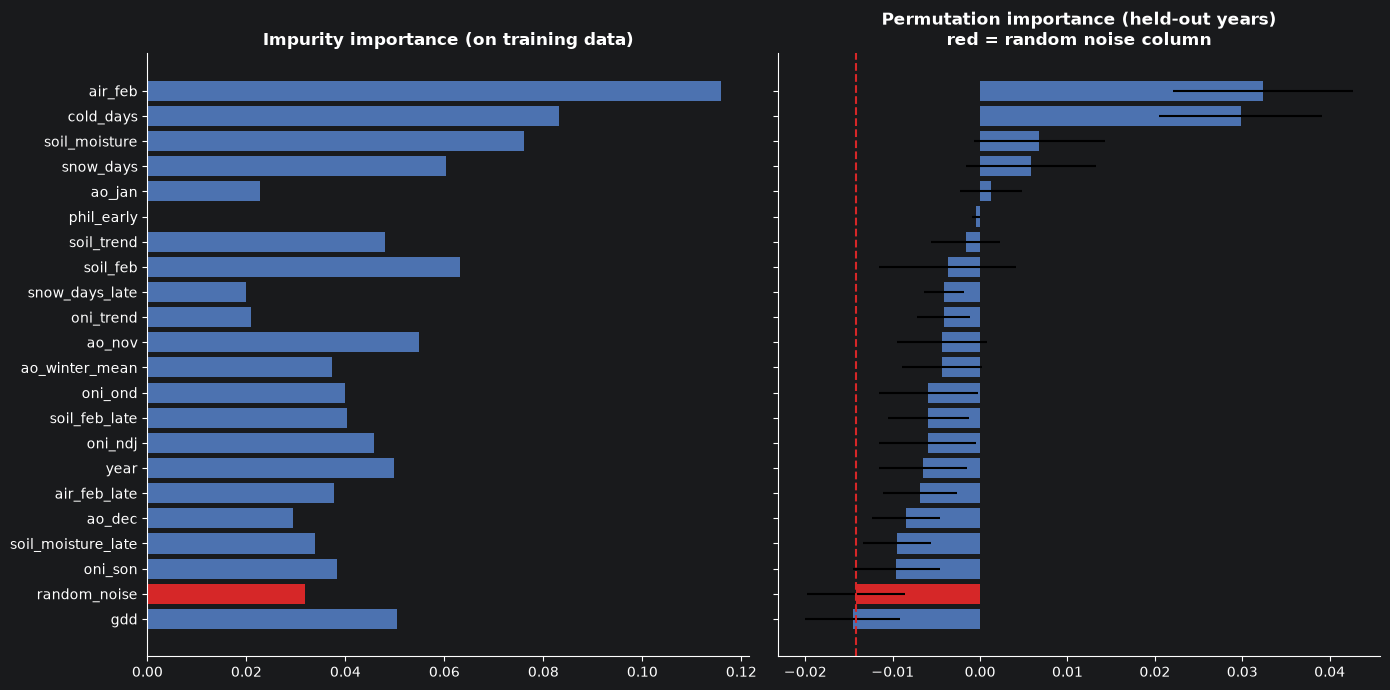

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharey=True)
order = importance.index[::-1]
noise_color = ["#d62728" if f == "random_noise" else "#4c72b0" for f in order]
axes[0].barh(order, importance.loc[order, "impurity importance"], color=noise_color)
axes[0].set_title("Impurity importance (on training data)", fontweight="bold")
axes[1].barh(order, importance.loc[order, "permutation (AUC drop)"],
             xerr=importance.loc[order, "permutation sd"] / np.sqrt(len(perm)), color=noise_color)
axes[1].axvline(importance.loc["random_noise", "permutation (AUC drop)"], color="#d62728", linestyle="--")
axes[1].set_title("Permutation importance (held-out years)\nred = random noise column", fontweight="bold")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**How to read this.** The **left** chart (impurity) spreads importance over many features, including weak ones, because it is measured on the data the forest was trained on. The **right** chart (permutation, on held-out years) is stricter: most features barely change the held-out AUC when shuffled, and the error bars are wide.

**What we learn:**

* **`air_feb`** and **`cold_days`** are the clearest signals: shuffling either one lowers the held-out AUC the most (they are the same information, r = −0.91, so the forest uses them interchangeably).
* **`soil_moisture`** and **`snow_days`** come next, with a small but positive effect.
* **Everything else is at about zero**: shuffling it does not hurt held-out years. That includes all the **soil-temperature** features (February soil is stuck near 0 °C, see Exploration), the late-February versions of air and snow, **all ONI and AO features**, and `year`.
* **Phil's call has an impurity importance of exactly 0**: the forest never even uses it to split.
* **`gdd` is no better than the random-noise column.**
* Notice how wide the error bars are. With 57 years, the order of the weak features is basically random; only the top 4 stand out.

In [11]:
# Importance per group of redundant features (members of a group share importance, so look at the sum)
group_of = {f: g for g, members in prep.REDUNDANT_GROUPS.items() for f in members}
group_imp = (importance.drop(index="random_noise")
             .assign(group=lambda d: d.index.map(lambda f: group_of.get(f, f)))
             .groupby("group")[["impurity importance", "permutation (AUC drop)"]].sum()
             .sort_values("permutation (AUC drop)", ascending=False))
group_imp.round(3)

,impurity importance,permutation (AUC drop)
group,,
february cold,0.287,0.041
snow,0.080,0.002
phil_early,0.000,-0.000
soil moisture,0.110,-0.003
year,0.050,-0.007
soil temp,0.151,-0.011
AO,0.144,-0.016
ONI,0.145,-0.026


Adding up the importance per group confirms the picture: **February cold** is by far the most useful group, then snow and soil moisture. The soil-temperature, ONI and AO groups are *negative* in total: shuffling them slightly *helps* on held-out years, which means the forest was partly fitting noise with them.

### 2c. The feature sets

From the clusters, the random forest and Exploration we define three feature sets in `early_spring_prep.py`. They are a tunable hyperparameter of the preprocessor:

In [12]:
# The feature sets that come out of this (defined in early_spring_prep.py)
for name, cols in prep.FEATURE_SETS.items():
    n = X_train.shape[1] if cols is None else len(cols)
    print(f"{name:9s} ({n:2d} columns): {'every column' if cols is None else ', '.join(cols)}")

all       (21 columns): every column
selected  ( 9 columns): year, air_feb, cold_days, gdd, snow_days, soil_feb, soil_moisture, oni_ndj, ao_nov
small     ( 4 columns): year, air_feb, snow_days, soil_moisture


* **`all`**: everything, as a reference.
* **`selected`**: one or two features per redundant group (`air_feb` + `cold_days`, `snow_days`, `soil_feb`, `soil_moisture`, `gdd`), the strongest-correlated ONI (`oni_ndj`) and AO (`ao_nov`) features, and `year`.
* **`small`**: only the 4 features that clearly carried information: `air_feb` (for the cold/snow cluster we keep `air_feb` rather than `cold_days`, since they are nearly the same), `snow_days`, `soil_moisture`, plus `year` for the climate trend.

Now we check that removing features actually helps, using the same two models:

In [13]:
# Do fewer features actually help? Same random forest and logistic regression, three feature sets.
rows = {}
for fs in ["all", "selected", "small"]:
    rows[("random forest", fs)] = evaluate(
        RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1),
        feature_set=fs)
    rows[("logistic regression C=0.1", fs)] = evaluate(LogisticRegression(C=0.1, max_iter=5000), feature_set=fs)
set_results = pd.DataFrame(rows).T.round(3)
set_results

,,train AUC,CV AUC,CV AUC sd,train profit,CV profit
random forest,all,0.997,0.618,0.191,0.124,0.044
logistic regression C=0.1,all,0.860,0.654,0.170,0.075,0.032
random forest,selected,0.987,0.697,0.199,0.125,0.061
logistic regression C=0.1,selected,0.837,0.731,0.173,0.074,0.052
random forest,small,0.969,0.705,0.191,0.124,0.035
logistic regression C=0.1,small,0.825,0.768,0.165,0.069,0.056


**Fewer features generalize better.** For both models the train AUC goes *down* as we drop features, while the CV AUC goes *up* (logistic regression: 0.66 → 0.74 → 0.77; random forest: 0.62 → 0.70 → 0.71). That is the signature of **overfitting being reduced**: the extra columns were helping the models memorize the training years, not predict new ones. The random forest shows it most: train AUC ≈ 0.97–1.0, CV ≈ 0.6–0.7.

**Decision: `small` is the default feature set**, with `selected` and `all` still available as options when tuning in the Training notebook.

# 3. Feature engineering

### 3a. Skewed features → `log1p`?

In [14]:
# Effect of log1p on the skewed features
skewed = X_train[prep.SKEWED].astype(float)
pd.DataFrame({"skew before": skewed.skew(), "skew after log1p": np.log1p(skewed).skew()}).round(2)

,skew before,skew after log1p
gdd,0.97,-1.09


In Exploration only `gdd` was clearly skewed (many cold winters with very few growing degree days). `log1p` (= log(1 + x), which works for 0) **over-corrects** it: the skew flips from +0.97 to −1.09. And `gdd` turned out not to matter (section 2). So the transform stays available (`log_skewed`) but is **off by default**.

### 3b. The other engineered features

Each is switched on one at a time, starting from the `selected` set with no engineering (it contains `gdd` and `cold_days`, which these options need):

* **`log1p`** of `gdd` (above).
* **`cold_and_snowy`** flag: the manual rule from Exploration (more snow-cover days *and* more cold days than the median). The medians are learned in `fit`, so in cross-validation they come from the training folds only.
* **Missing flags**: `indices_missing` (1947–1950) and `air_missing` (2004).
* **Without `year`**: does the climate trend help?
* **With Phil**: does Phil's call help?

In [15]:
# Do the engineered features help? Switch them on one at a time
# (logistic regression on the 'selected' set, which has gdd for the log1p and cold_days for the rule flag)
lr = LogisticRegression(C=0.1, max_iter=5000)
base = dict(feature_set="selected", log_skewed=False, add_rule_flag=False, add_missing_flags=False)
variants = {
    "no engineering":             base,
    "+ log1p of gdd":             base | {"log_skewed": True},
    "+ cold_and_snowy rule flag": base | {"add_rule_flag": True},
    "+ missing flags":            base | {"add_missing_flags": True},
    "without year":               base | {"use_year": False},
    "+ Phil":                     base | {"feature_set": prep.FEATURE_SETS["selected"] + ["phil_early"]},
}
eng_results = pd.DataFrame({name: evaluate(lr, **p) for name, p in variants.items()}).T.round(3)
eng_results

,train AUC,CV AUC,CV AUC sd,train profit,CV profit
no engineering,0.837,0.731,0.173,0.074,0.052
+ log1p of gdd,0.839,0.739,0.181,0.076,0.053
+ cold_and_snowy rule flag,0.843,0.728,0.174,0.075,0.052
+ missing flags,0.837,0.715,0.165,0.075,0.049
without year,0.823,0.735,0.179,0.067,0.049
+ Phil,0.848,0.727,0.174,0.073,0.053


**What we learn (remember: differences below ~0.02–0.03 AUC are within the noise):**

* **`log1p` of `gdd`**: +0.008, within the noise. **Off by default.**
* The **`cold_and_snowy` flag** adds nothing: the model can already build the same rule from `snow_days` and `cold_days`. **Off by default.**
* The **missing flags** slightly hurt (they mark only 5 training years). **Off by default.**
* **`year`**: removing it barely changes CV AUC, because inside the training years the trend is weak. But the test years are very different (47% early springs vs. 19%), and `year` is the only feature that can carry that trend forward. **Kept**, and `use_year` is tunable.
* **Phil** does not help, as expected. **Left out.**

### 3c. Polynomial features: are we underfitting?

The check-in suggested trying polynomial features, especially if the model underfits. Degree-2 polynomial features add the **square** of each feature and the **product** of every pair (e.g. `snow_days * air_feb`, the "warm *and* no snow" interaction we saw in Exploration). They let a linear model bend.

We only make them from the 3 strongest farm features (`air_feb`, `snow_days`, `soil_moisture`): degree 2 on all 21 columns would give ~250 columns for 57 rows.

To tell under- from overfitting we compare the **train** and **cross-validation** AUC of a logistic regression over a wide range of regularization strengths `C` (small `C` = simple model, large `C` = flexible model):

* **Underfitting**: train and CV scores are both low and close together. A more flexible model (bigger `C`, polynomial features) would raise both.
* **Overfitting**: train score is much higher than CV. More flexibility makes CV *worse*.

In [16]:
# Under- or overfitting? Logistic regression with and without degree-2 polynomial features,
# over a range of regularization strengths (small C = strong regularization = simpler model).
rows = {}
for fs in ["small", "selected"]:
    for degree in [1, 2]:
        for C in [0.01, 0.1, 1, 10]:
            rows[(fs, degree, C)] = evaluate(LogisticRegression(C=C, max_iter=10000),
                                             feature_set=fs, poly_degree=degree)
poly_results = pd.DataFrame(rows).T.rename_axis(["feature set", "degree", "C"]).round(3)
poly_results["gap (train - CV AUC)"] = (poly_results["train AUC"] - poly_results["CV AUC"]).round(3)
poly_results

train AUC  CV AUC  CV AUC sd  train profit  \
feature set degree C                                                   
small       1      0.01       0.821   0.771      0.164         0.062   
                   0.10       0.825   0.768      0.165         0.069   
                   1.00       0.827   0.755      0.173         0.076   
                   10.00      0.828   0.749      0.171         0.078   
            2      0.01       0.818   0.736      0.186         0.068   
                   0.10       0.834   0.718      0.192         0.078   
                   1.00       0.872   0.686      0.215         0.096   
                   10.00      0.899   0.625      0.232         0.096   
selected    1      0.01       0.817   0.750      0.183         0.065   
                   0.10       0.837   0.731      0.173         0.074   
                   1.00       0.871   0.664      0.164         0.091   
                   10.00      0.895   0.629      0.184         0.098   
            2      0.01       0.815   0.737      0.199         0.072   
                   0.10       0.850   0.708      0.194         0.078   
                   1.00       0.908   0.616      0.198         0.103   
                   10.00      0.956   0.567      0.215         0.117   

                          CV profit  gap (train - CV AUC)  
feature set degree C                                       
small       1      0.01       0.037                 0.050  
                   0.10       0.056                 0.057  
                   1.00       0.052                 0.072  
                   10.00      0.050                 0.079  
            2      0.01       0.043                 0.082  
                   0.10       0.055                 0.116  
                   1.00       0.044                 0.186  
                   10.00      0.029                 0.274  
selected    1      0.01       0.051                 0.067  
                   0.10       0.052                 0.106  
                   1.00       0.034                 0.207  
                   10.00      0.025                 0.266  
            2      0.01       0.058                 0.078  
                   0.10       0.056                 0.142  
                   1.00       0.026                 0.292  
                   10.00      0.018                 0.389

/var/folders/1d/h583rbfj6cx29980b7ysz3000000gp/T/ipykernel_35836/2071105907.py:4: PerformanceWarning: indexing past lexsort depth may impact performance.
  r = poly_results.loc[(fs, degree)]


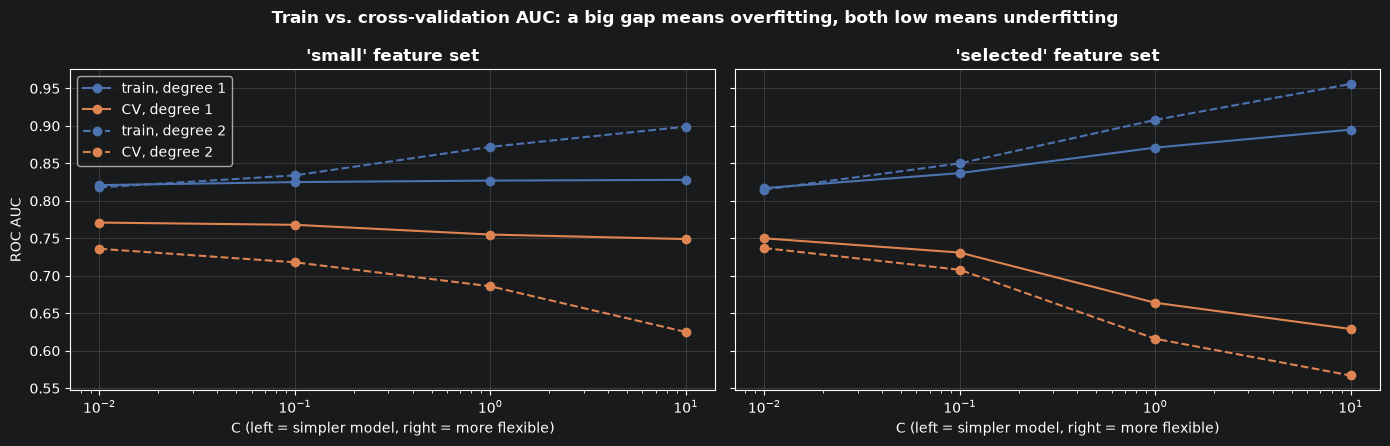

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, fs in zip(axes, ["small", "selected"]):
    for degree, style in [(1, "-"), (2, "--")]:
        r = poly_results.loc[(fs, degree)]
        ax.plot(r.index, r["train AUC"], style, marker="o", color="#4c72b0", label=f"train, degree {degree}")
        ax.plot(r.index, r["CV AUC"], style, marker="o", color="#dd8452", label=f"CV, degree {degree}")
    ax.set_xscale("log")
    ax.set_xlabel("C (left = simpler model, right = more flexible)")
    ax.set_title(f"'{fs}' feature set", fontweight="bold")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("ROC AUC")
axes[0].legend()
plt.suptitle("Train vs. cross-validation AUC: a big gap means overfitting, both low means underfitting",
             fontweight="bold")
plt.tight_layout()
plt.show()

**Polynomial features don't help; the problem is too little data, not a too-simple model:**

* With the `small` set and no polynomial features, train AUC ≈ 0.82–0.83 and CV AUC ≈ 0.75–0.77 at every `C`: a small gap (0.05–0.08). The 4-feature linear model is about as good on new years as on its own training years, so it is not badly overfitting.
* Is it *underfitting*? If it were, a more flexible model would raise the CV score. It doesn't: **adding degree-2 features lowers CV AUC at every `C`** (0.77 → 0.74 at `C = 0.01`, down to 0.63 at `C = 10`), while the train score rises to 0.90. The extra flexibility only memorizes the training years.
* The bigger `selected` set shows the same thing, more strongly (train 0.96 vs. CV 0.58 at degree 2, `C = 10`).

**Decision: no polynomial features by default (`poly_degree=1`).** They stay available as a tunable option (`poly_degree`, `interaction_only`) in case a model in the Training notebook does underfit. Tree models find interactions on their own and don't need them.

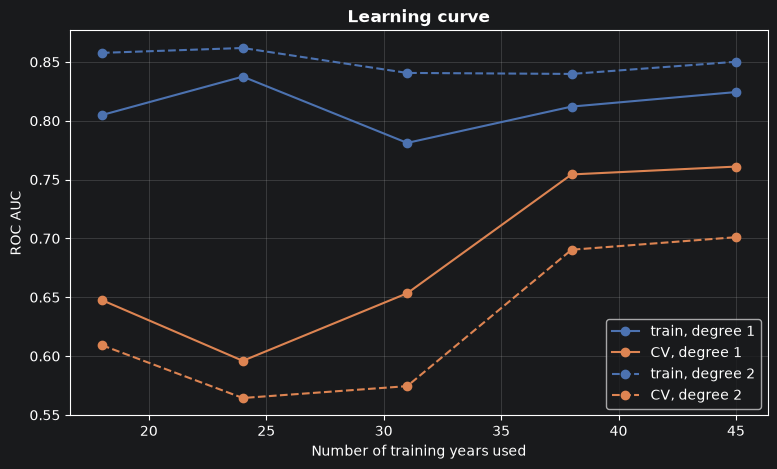

In [18]:
# Learning curve: would more years help? (logistic regression, 'small' set, degree 1 vs 2)
fig, ax = plt.subplots(figsize=(9, 5))
for degree, style in [(1, "-"), (2, "--")]:
    pipe = Pipeline([("prep", make_preprocessor(feature_set="small", poly_degree=degree)),
                     ("model", LogisticRegression(C=0.3, max_iter=10000))])
    sizes, tr, va = learning_curve(pipe, X_train, y_train, cv=CV, scoring="roc_auc",
                                   train_sizes=np.linspace(0.4, 1.0, 5), n_jobs=-1)
    ax.plot(sizes, tr.mean(axis=1), style, marker="o", color="#4c72b0", label=f"train, degree {degree}")
    ax.plot(sizes, va.mean(axis=1), style, marker="o", color="#dd8452", label=f"CV, degree {degree}")
ax.set_xlabel("Number of training years used")
ax.set_ylabel("ROC AUC")
ax.set_title("Learning curve", fontweight="bold")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

The learning curve shows why: the CV score is **still climbing** at the full 45 years per fold (from ~0.60 with 24 years to ~0.76 with 45), while the train score stays flat. **More years would help more than more features.** We can't get more years, so the best we can do is keep the model simple: few features and strong regularization. The degree-2 curve (dashed) is above on train and below on CV at every size: polynomial features only widen the gap.

# 4. Feature scaling

In [19]:
# Standard vs. robust scaling (they only matter for distance/linear models, not for trees)
lr = LogisticRegression(C=0.1, max_iter=5000)
pd.DataFrame({s: evaluate(lr, feature_set="small", scaler=s) for s in ["standard", "robust", "none"]}).T.round(3)

,train AUC,CV AUC,CV AUC sd,train profit,CV profit
standard,0.825,0.768,0.165,0.069,0.056
robust,0.816,0.778,0.166,0.067,0.056
none,0.810,0.753,0.172,0.075,0.055


Logistic regression (and SVMs, KNN) need features on similar scales: otherwise `year` (≈ 2000) and `soil_moisture` (≈ 0.47) get very different penalties from the regularization, and KNN distances are dominated by the largest numbers. Without scaling the CV AUC drops clearly.

**Standard** scaling (mean 0, standard deviation 1) and **robust** scaling (median 0, IQR 1, less affected by extreme winters) give similar results (0.77 vs. 0.78 CV AUC, within the noise). **Decision: `StandardScaler` by default**; the scaler is tunable (`prep__scale__step`), and `RobustScaler` is worth including in the Training grid search. Tree models don't care about scaling.

# 5. The preprocessor

Putting the decisions together. The pipeline is:

1. **`FeatureEngineer`**: drop the label if present, turn `phil_early` into 0/1, keep the `small` feature set (`year`, `air_feb`, `snow_days`, `soil_moisture`).
2. **Impute**: fill remaining gaps with the training median (in practice, `air_feb` for 2004).
3. **Scale**: `StandardScaler`.
4. **Polynomial features**: off (degree 1).

In [20]:
# The final preprocessor: the defaults chosen above
preprocessor = make_preprocessor(
    feature_set="small",        # year, air_feb, snow_days, soil_moisture
    log_skewed=False,           # log1p of gdd: over-corrects the skew, no real gain (still tunable)
    add_rule_flag=False,        # cold_and_snowy flag: no gain (still tunable)
    add_missing_flags=False,    # missing flags: no gain (still tunable)
    impute_strategy="median",   # fill the few gaps with the training median
    scaler="standard",          # mean 0, sd 1
    poly_degree=1,              # no polynomial features by default (they overfit, see above)
)
preprocessor.fit(X_train, y_train)

X_train_ready = preprocessor.transform(train_set)
print(f"Ready to train: {X_train_ready.shape[0]} rows x {X_train_ready.shape[1]} columns, "
      f"{int(X_train_ready.isna().sum().sum())} missing values")
X_train_ready.describe().T[["mean", "std", "min", "max"]].round(2)

Ready to train: 57 rows x 4 columns, 0 missing values


,mean,std,min,max
year,0.0,1.01,-1.66,1.73
air_feb,-0.0,1.01,-2.84,1.91
snow_days,0.0,1.01,-1.60,1.87
soil_moisture,-0.0,1.01,-2.29,2.14


After preparation the training data has no missing values and every column has mean 0 and standard deviation 1. Next we check the requirement from the assignment: the same preprocessor must work on the **test set** and on anything **`generate_samples()`** returns (same columns, no label, Phil as a nullable boolean).

In [21]:
# The preprocessor must work on: the train set, the test set, and anything generate_samples() returns
# (same columns as the sets, without the label, and Phil as a nullable boolean).
X_test_ready = preprocessor.transform(test_set)
like_generate_samples = test_set.drop(columns=TARGET).astype({"phil_early": "boolean"})
X_gen_ready = preprocessor.transform(like_generate_samples)

assert list(X_test_ready.columns) == list(X_train_ready.columns)
assert X_test_ready.isna().sum().sum() == 0
pd.testing.assert_frame_equal(X_test_ready, X_gen_ready)           # the label column is ignored
assert np.allclose(preprocessor.transform(train_set.drop(columns=TARGET)), X_train_ready)
print("Train, test and generate_samples()-style input all give the same", X_train_ready.shape[1], "columns. OK")
X_test_ready.head().round(2)

Train, test and generate_samples()-style input all give the same 4 columns. OK


,year,air_feb,snow_days,soil_moisture
0,1.84,0.93,-1.24,-0.55
1,1.89,-0.61,-0.64,0.61
2,1.94,-1.71,1.51,1.30
3,2.00,-3.01,1.51,-0.19
4,2.05,0.27,-0.40,0.17


In [22]:
with open("preprocessor.pkl", "wb") as f:
    pickle.dump(preprocessor, f)

# Load it back the way the Training notebook will, and make sure it gives the same result
with open("preprocessor.pkl", "rb") as f:
    reloaded = pickle.load(f)
pd.testing.assert_frame_equal(reloaded.transform(test_set), X_test_ready)
print("preprocessor.pkl saved and reloaded OK")

preprocessor.pkl saved and reloaded OK


`preprocessor.pkl` is saved. To use it in the Training notebook:

```python
import pickle
import early_spring_prep   # must be importable, so pickle can find the classes
preprocessor = pickle.load(open("preprocessor.pkl", "rb"))
```

For tuning, the Training notebook should **not** use the fitted pickle but put `make_preprocessor()` in front of each model inside a `Pipeline`, so the preprocessing is re-fitted inside every CV fold and its settings can be tuned together with the model's:

In [23]:
# Every preprocessing hyperparameter that the Training notebook can tune (inside a Pipeline named "prep")
pd.DataFrame([
    ("prep__features__feature_set",       "'all', 'selected', 'small'",  "which columns to keep"),
    ("prep__features__log_skewed",        "True / False",                "log1p of skewed features"),
    ("prep__features__add_rule_flag",     "True / False",                "manual-rule flag cold_and_snowy"),
    ("prep__features__add_missing_flags", "True / False",                "indices_missing / air_missing flags"),
    ("prep__features__use_year",          "True / False",                "keep the year (trend)"),
    ("prep__features__use_phil",          "True / False",                "keep Phil's call"),
    ("prep__features__use_indices",       "True / False",                "keep ONI / AO"),
    ("prep__impute__step__strategy",      "'median', 'mean'",            "how to fill the few gaps"),
    ("prep__scale__step",                 "StandardScaler(), RobustScaler(), 'passthrough'", "scaling"),
    ("prep__poly__degree",                "1, 2",                        "polynomial features on the strongest columns"),
    ("prep__poly__interaction_only",      "True / False",                "only products, no squares"),
], columns=["parameter", "values", "what it does"])

,parameter,values,what it does
0,prep__features__feature_set,"'all', 'selected', 'small'",which columns to keep
1,prep__features__log_skewed,True / False,log1p of skewed features
2,prep__features__add_rule_flag,True / False,manual-rule flag cold_and_snowy
3,prep__features__add_missing_flags,True / False,indices_missing / air_missing flags
4,prep__features__use_year,True / False,keep the year (trend)
5,prep__features__use_phil,True / False,keep Phil's call
6,prep__features__use_indices,True / False,keep ONI / AO
7,prep__impute__step__strategy,"'median', 'mean'",how to fill the few gaps
8,prep__scale__step,"StandardScaler(), RobustScaler(), 'passthrough'",scaling
9,prep__poly__degree,"1, 2",polynomial features on the strongest columns


# What we learned / notes for the Training notebook

1. **Outliers are real winters**, not errors; we keep them.
2. **Missing cells** (5 years, 2.8% of cells) are filled with the training median; dropping rows would lose an early spring (1949).
3. **The random forest** (used only for information) and the clustering agree: February cold (`air_feb`/`cold_days`) carries most of the signal, then snow cover and soil moisture. Soil temperature, ONI, AO, `gdd` and Phil add nothing on top.
4. **Fewer features generalize better**: `small` > `selected` > `all` in cross-validation for both a linear model and a random forest.
5. **Polynomial features hurt** (CV AUC drops at every regularization strength); the models need more data, not more flexibility. They stay as a tunable option.
6. **Scores are noisy** (sd of CV AUC ≈ 0.17): only trust differences larger than ~0.03, and prefer the simpler option when two are close.
7. **For Training:** load `early_spring_prep` in every notebook *before* unpickling; tune the preprocessing together with each model (`prep__...` parameters above); use `profit_score` (threshold 0.2) or tune the threshold; compare against the baselines from Exploration (never buy, always buy, Phil, the manual rule). The test years have far more early springs (47%) than the training years (19%), so check that the chosen model still buys often enough when the base rate rises.